# Gerçek OpenMC 3B enerji üretimi yaklaşımı ve PCA/POD

Bu notebook, **gerçek OpenMC kappa-fission tally** verisini inceler. Alan, toplam yerel ısı birikimi veya gerçek reaktörün mutlak güç haritası değildir. Normalize hedefin birimi yoktur; ham kappa-fission ortalaması ve MC standart hatası eV/kaynak parçacığı birimindedir.

**PROVISIONAL:** 256 alanın tamamı bilimsel inceleme bekliyor. Sıfır ölçüm fiziksel sıfır veya sıfır belirsizlik sayılmaz. Normalize hedef için kovaryans dahil kesin belirsizlik mevcut değildir. PCA yalnız 208 sabit eğitim senaryosunda öğrenilir; 25 kalibrasyon ve 23 test senaryosu bileşen seçimine katılmaz. Bu notebook 3B regresyon modeli eğitmez, MC başlatmaz.


## 1. Kaynak, düzen ve doğrulama
Alan eksenleri [senaryo,z,y,x]. Düzleştirme C sırasındadır: x en hızlı, sonra y, sonra z. Satırlar katalog ve scenarios.csv sırasındadır. Fiziksel x/y hücre kenarları adım parametresine göre değişebilir; PCA ortak **mesh indeksi** uzayındadır, sabit cm koordinatlarında enterpolasyon değildir.

In [1]:
import csv, hashlib, json, os, sys, time
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
ROOT = Path('/home/ascanipek/openmc-proje')
if not ROOT.is_dir():
    ROOT = Path.cwd().resolve()
    if not (ROOT/'datasets/v2_256_preview_v1/fields.npz').is_file():
        raise FileNotFoundError('Projeyi kök dizinden açın veya ROOT yolunu ayarlayın.')
DATA = ROOT/'datasets/v2_256_preview_v1'
OUT = ROOT/'reports/field3d_pca_v1'
OUT.mkdir(parents=True,exist_ok=True)
with (DATA/'scenarios.csv').open(newline='',encoding='utf-8') as f:
    scenarios=list(csv.DictReader(f))
splits=json.loads((DATA/'splits.json').read_text())
manifest=json.loads((DATA/'dataset_manifest.json').read_text())
assert len(scenarios)==256 and manifest['scenario_count']==256
assert manifest['array_order']==['sample','z','y','x'] and manifest['mesh_shape_zyx']==[20,17,17]
assert hashlib.sha256((ROOT/'scenarios/v2_students_portable_v1/catalogue_total_256.json').read_bytes()).hexdigest()==manifest['catalogue_sha256']
role={sid:k for k in ('train','calibration','test') for sid in splits[k]}
assert {k:len(splits[k]) for k in ('train','calibration','test')}=={'train':208,'calibration':25,'test':23}
assert len(role)==256 and len({s['scenario_id'] for s in scenarios})==256
assert all(int(s['row'])==i and s['split']==role[s['scenario_id']] for i,s in enumerate(scenarios))
train_idx=np.array([i for i,s in enumerate(scenarios) if s['split']=='train'])
assert len(train_idx)==208
print('Kaynak:',DATA/'fields.npz','\nSplit: 208 eğitim / 25 kalibrasyon / 23 test')


Kaynak: /home/ascanipek/openmc-proje/datasets/v2_256_preview_v1/fields.npz 
Split: 208 eğitim / 25 kalibrasyon / 23 test


In [2]:
with np.load(DATA/'fields.npz') as source:
    normalized=source['target_normalized_kappa']
    raw=source['kappa_fission_mean']
    raw_se=source['kappa_fission_std_dev']
    fission=source['fission_mean']
    fission_se=source['fission_std_dev']
    fuel_fraction=source['fuel_volume_fraction']
    x_edges=source['x_edges_cm']
    y_edges=source['y_edges_cm']
    z_edges=source['z_edges_cm']
assert normalized.shape==raw.shape==(256,20,17,17)
fuel=fuel_fraction>0
assert np.isfinite(normalized).all() and np.isfinite(raw).all() and np.isfinite(raw_se).all()
assert (normalized>=0).all() and (raw>=0).all() and (raw_se>=0).all()
assert (fuel.sum(axis=(1,2,3))==5280).all()
assert np.count_nonzero(normalized[~fuel])==0
assert np.allclose(normalized.sum(axis=(1,2,3)),1.0,rtol=0,atol=2e-12)
raw_sum=np.sum(raw*fuel,axis=(1,2,3))
assert (raw_sum>0).all()
assert np.allclose(normalized,raw/raw_sum[:,None,None,None],rtol=1e-9,atol=1e-14)
print('Şekil:',normalized.shape,'; mesh voxel:',20*17*17,'; yakıt voxel/senaryo:',fuel[0].sum())
print('Negatif ham/hedef:',np.count_nonzero(raw<0),np.count_nonzero(normalized<0))
print('Normalize toplam aralığı:',normalized.sum(axis=(1,2,3)).min(),normalized.sum(axis=(1,2,3)).max())
print('Yakıt maskesi bütün senaryolarda aynı:',bool(np.all(fuel==fuel[0])))
print('Fiziksel X kenarları bütün senaryolarda aynı:',bool(np.all(x_edges==x_edges[0])))


Şekil: (256, 20, 17, 17) ; mesh voxel: 5780 ; yakıt voxel/senaryo: 5280
Negatif ham/hedef: 0 0
Normalize toplam aralığı: 0.9999999999999997 1.0000000000000004
Yakıt maskesi bütün senaryolarda aynı: True
Fiziksel X kenarları bütün senaryolarda aynı: False


## 2. Gerçek alan örnekleri ve düşük sinyal
Örnekler yalnız eğitim bölümünden, %0/%50/%100 girişe en yakın farklı senaryolardır. Düşük sinyal kuralı mevcut exporter ile aynıdır: yakıt ve (fission=0 veya fission<5×ham SE veya fission<10⁻⁶×senaryonun en büyük fission ortalaması). Sıfır kappa ayrıca işaretlenir; ölçüm sıfırı fiziksel sıfır değildir.

row 22 ID 32f89ffea9fdb0c2 giriş % 0.0 sıfır/yakıt 0 / 5280 düşük/yakıt 0 / 5280 üst 4 sıfır/düşük 0 0
row 0 ID a78b08c1951e6d40 giriş % 50.0 sıfır/yakıt 741 / 5280 düşük/yakıt 1648 / 5280 üst 4 sıfır/düşük 741 1056
row 23 ID 60986cdbbb72aa01 giriş % 100.0 sıfır/yakıt 0 / 5280 düşük/yakıt 557 / 5280 üst 4 sıfır/düşük 0 557


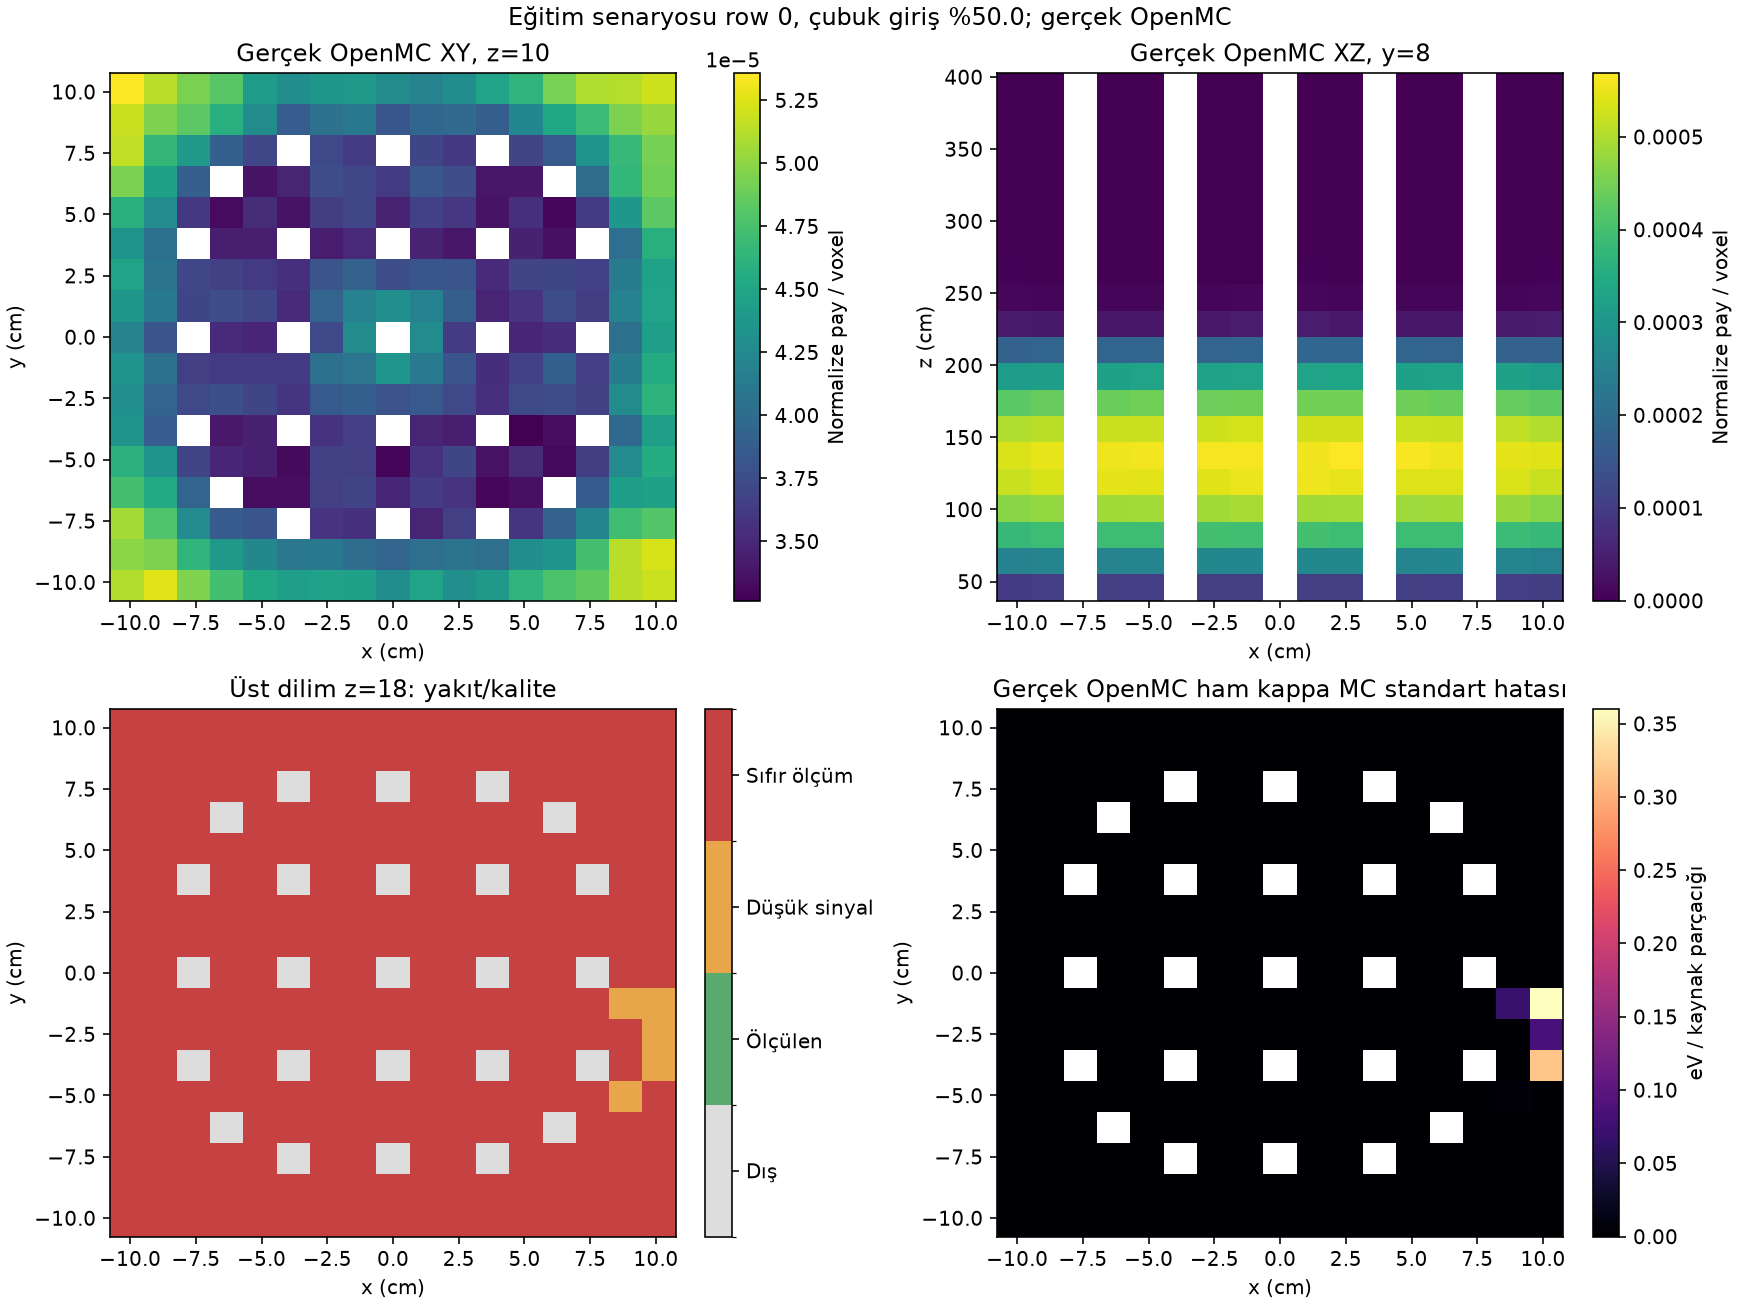

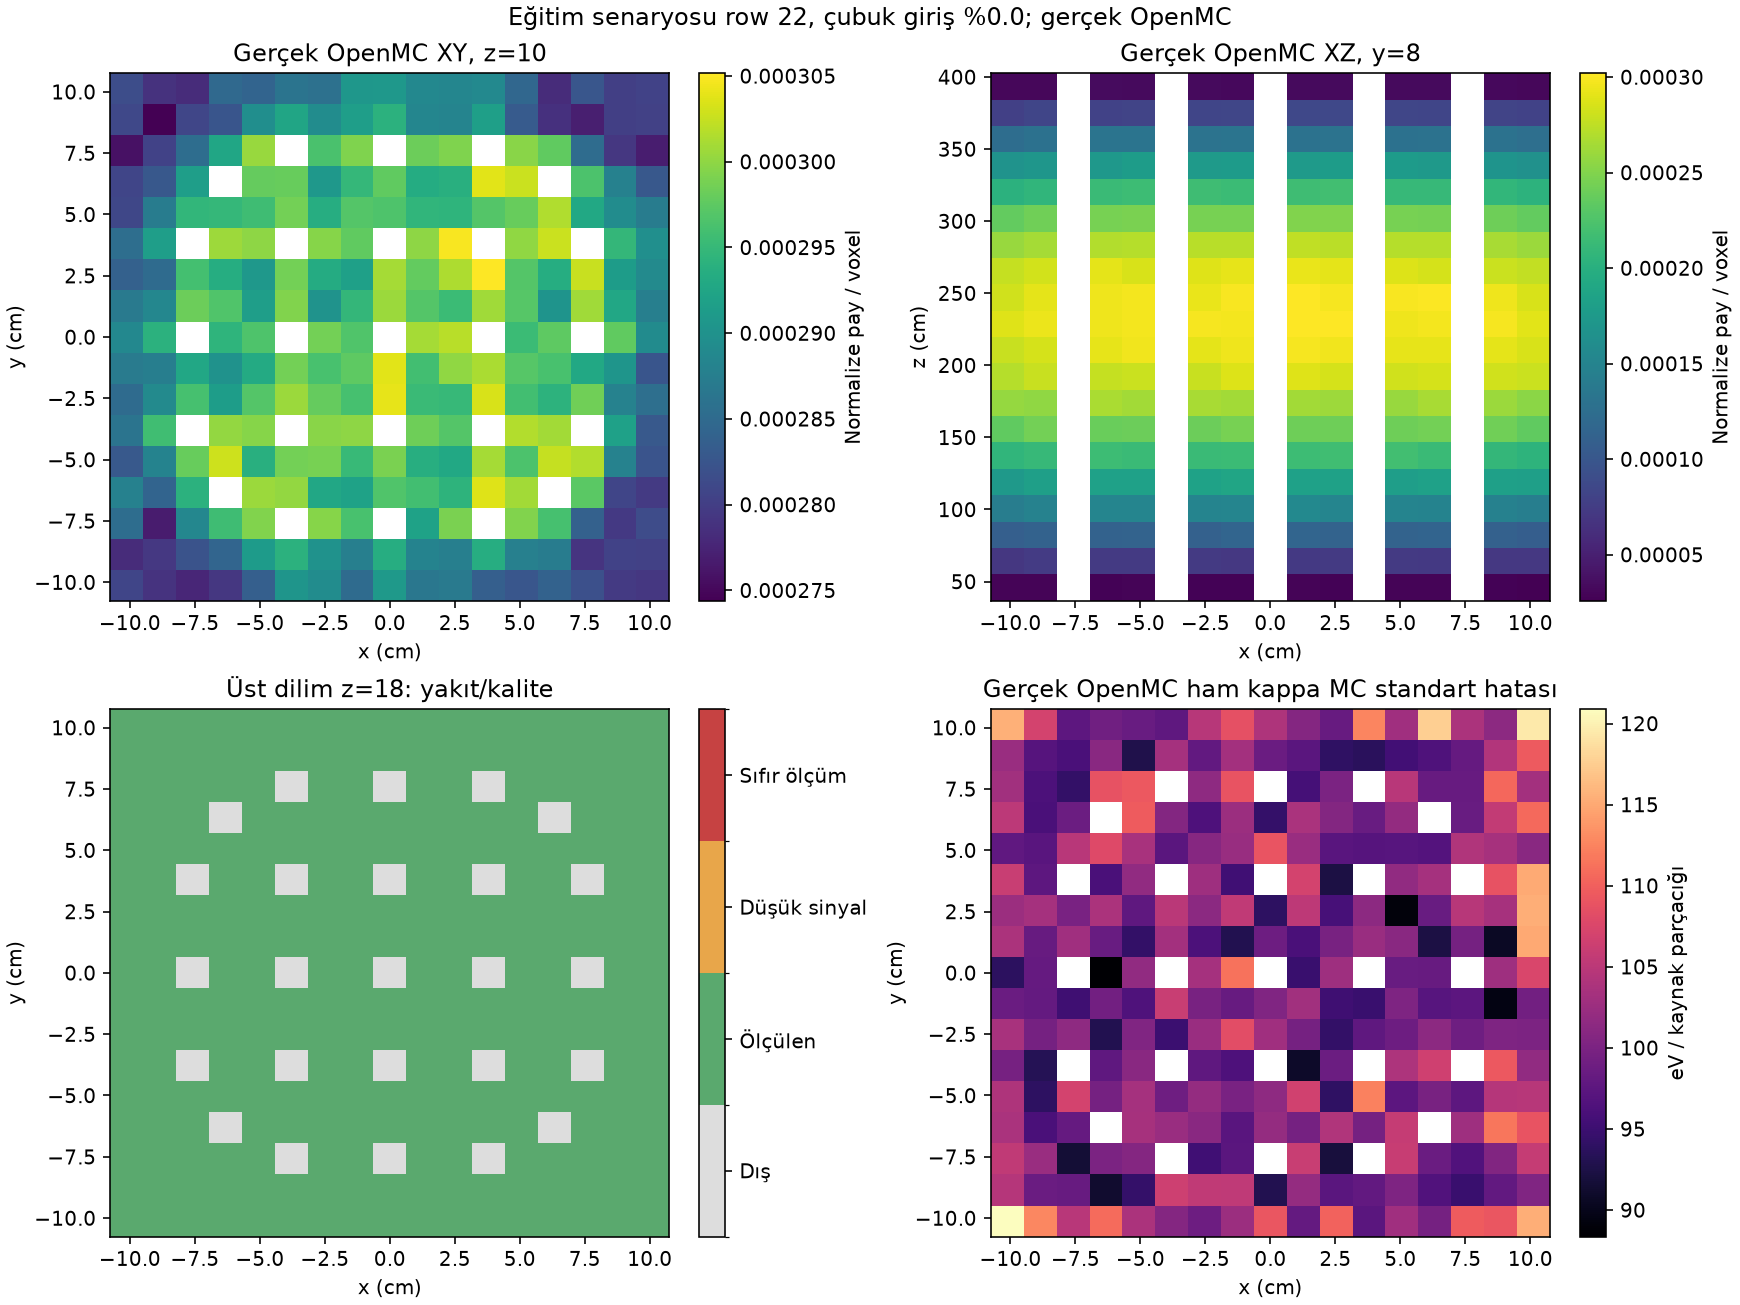

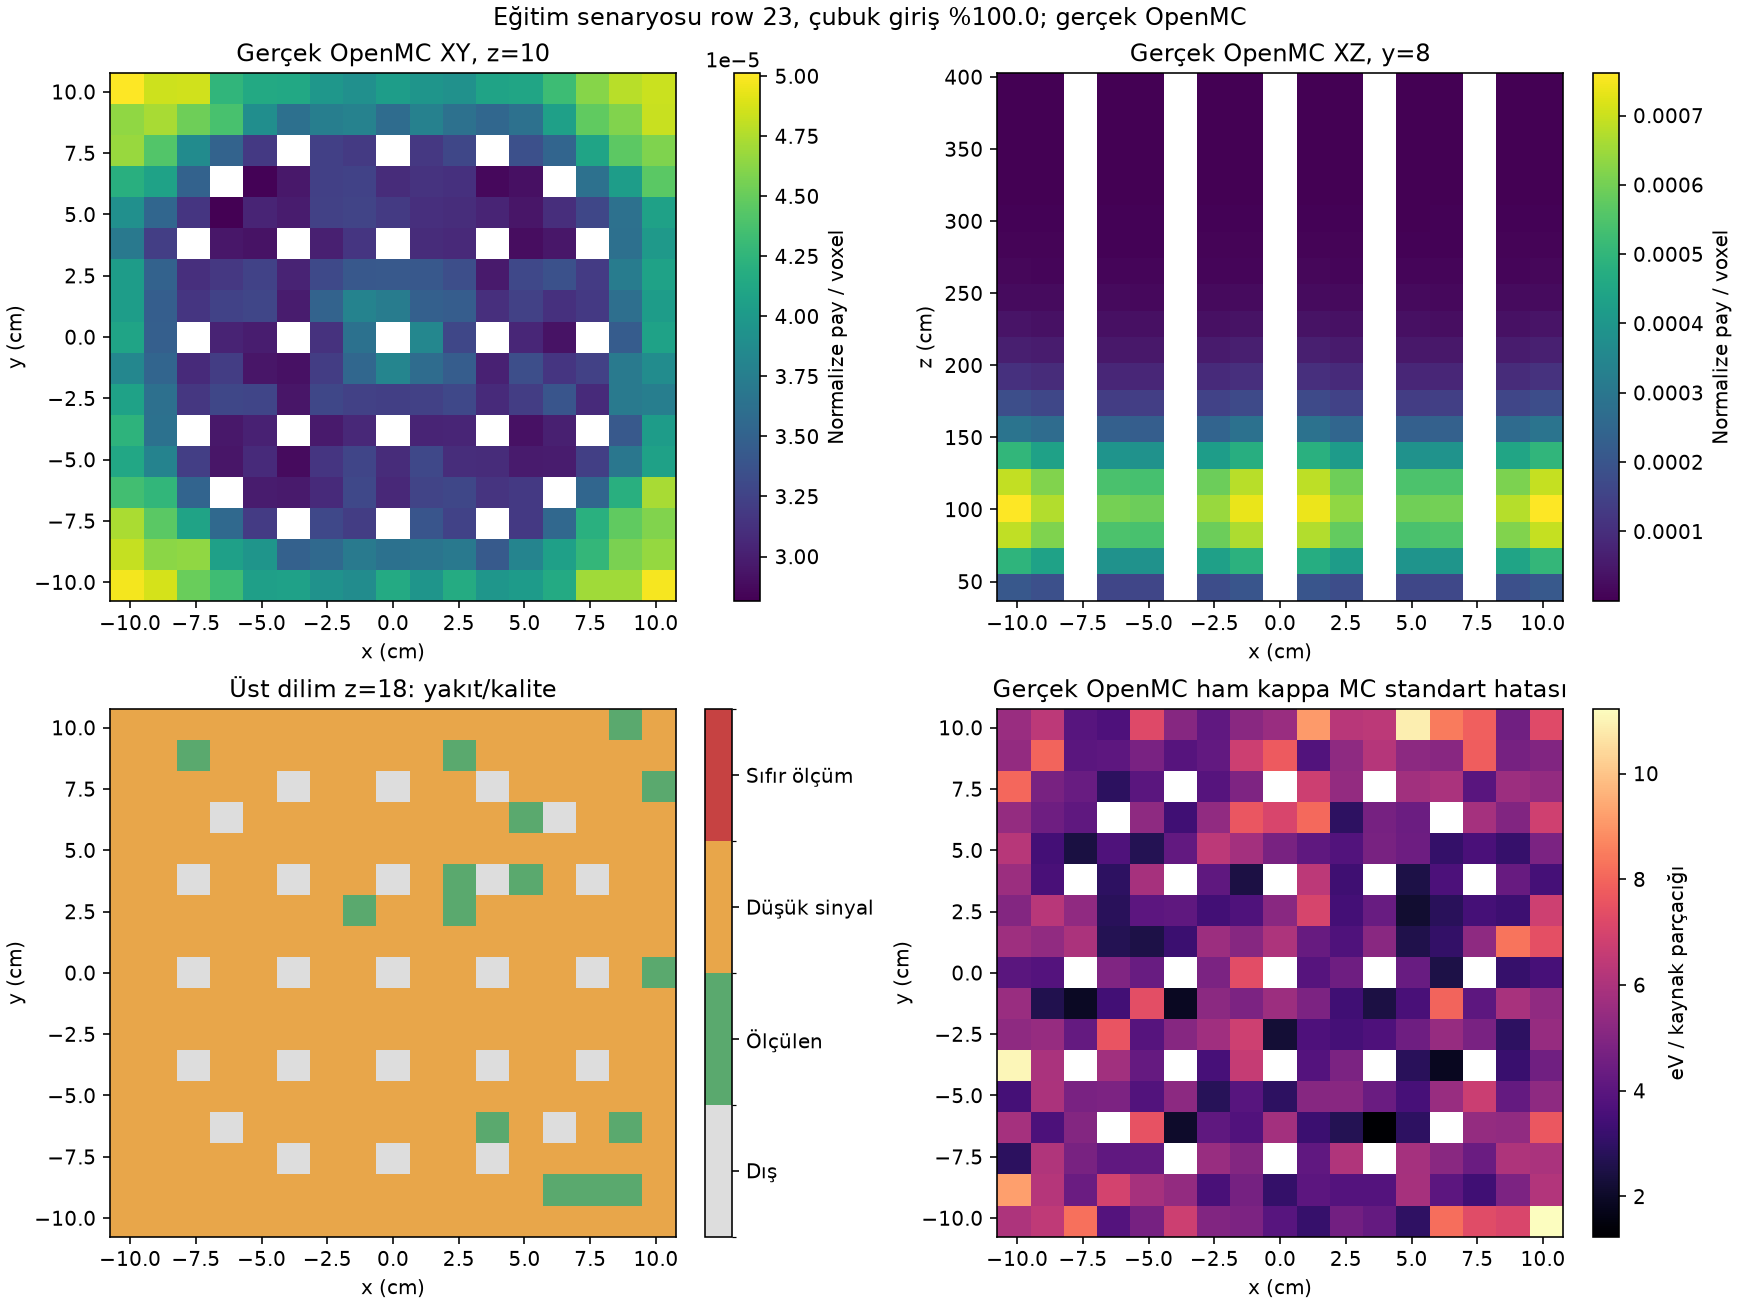

In [3]:
insertion=np.array([float(s['insertion_percent']) for s in scenarios])
chosen=[];used=set()
for goal in (0.,50.,100.):
    ix=min((int(i) for i in train_idx if int(i) not in used),key=lambda i:abs(insertion[i]-goal))
    chosen.append(ix);used.add(ix)
low=fuel & ((fission==0)|(fission<5*fission_se)|(fission<1e-6*fission.max(axis=(1,2,3))[:,None,None,None]))
zero=fuel & (raw==0)
from matplotlib.colors import ListedColormap, BoundaryNorm
category_map=ListedColormap(['#dddddd','#5aa96e','#e8a64a','#c64242'])
category_norm=BoundaryNorm([-0.5,0.5,1.5,2.5,3.5],4)
for i in chosen:
    print('row',i,'ID',scenarios[i]['scenario_id'][:16],'giriş %',round(insertion[i],3),
          'sıfır/yakıt',int(zero[i].sum()),'/',int(fuel[i].sum()),
          'düşük/yakıt',int(low[i].sum()),'/',int(fuel[i].sum()),
          'üst 4 sıfır/düşük',int(zero[i,-4:].sum()),int(low[i,-4:].sum()))
    fig,axes=plt.subplots(2,2,figsize=(12,9),constrained_layout=True)
    zmid=10;ymid=8;top=18
    xy=np.ma.masked_where(~fuel[i,zmid],normalized[i,zmid])
    xz=np.ma.masked_where(~fuel[i,:,ymid,:],normalized[i,:,ymid,:])
    im=axes[0,0].pcolormesh(x_edges[i],y_edges[i],xy,shading='flat',cmap='viridis')
    fig.colorbar(im,ax=axes[0,0],label='Normalize pay / voxel')
    axes[0,0].set(title=f'Gerçek OpenMC XY, z={zmid}',xlabel='x (cm)',ylabel='y (cm)')
    im=axes[0,1].pcolormesh(x_edges[i],z_edges[i],xz,shading='flat',cmap='viridis')
    fig.colorbar(im,ax=axes[0,1],label='Normalize pay / voxel')
    axes[0,1].set(title=f'Gerçek OpenMC XZ, y={ymid}',xlabel='x (cm)',ylabel='z (cm)')
    classes=np.zeros((17,17),dtype=int);classes[fuel[i,top]]=1
    classes[low[i,top]]=2;classes[zero[i,top]]=3
    im=axes[1,0].pcolormesh(x_edges[i],y_edges[i],classes,cmap=category_map,norm=category_norm,shading='flat')
    cb=fig.colorbar(im,ax=axes[1,0],ticks=[0,1,2,3])
    cb.ax.set_yticklabels(['Dış','Ölçülen','Düşük sinyal','Sıfır ölçüm'])
    axes[1,0].set(title=f'Üst dilim z={top}: yakıt/kalite',xlabel='x (cm)',ylabel='y (cm)')
    raw_image=np.ma.masked_where(~fuel[i,top],raw_se[i,top])
    im=axes[1,1].pcolormesh(x_edges[i],y_edges[i],raw_image,shading='flat',cmap='magma')
    fig.colorbar(im,ax=axes[1,1],label='eV / kaynak parçacığı')
    axes[1,1].set(title='Gerçek OpenMC ham kappa MC standart hatası',xlabel='x (cm)',ylabel='y (cm)')
    fig.suptitle(f'Eğitim senaryosu row {i}, çubuk giriş %{insertion[i]:.1f}; gerçek OpenMC')
    fig.savefig(OUT/f'openmc_real_fields_row_{i:03d}.png',dpi=145)
    plt.show();plt.close(fig)


Üst dört dilim payları: [(np.float64(0.0), [0.0450216, 0.0336951, 0.0215049, 0.0083588]), (np.float64(50.0), [2e-06, 3e-07, 0.0, 0.0]), (np.float64(100.0), [0.0003798, 0.0002061, 0.0001039, 3.94e-05])]


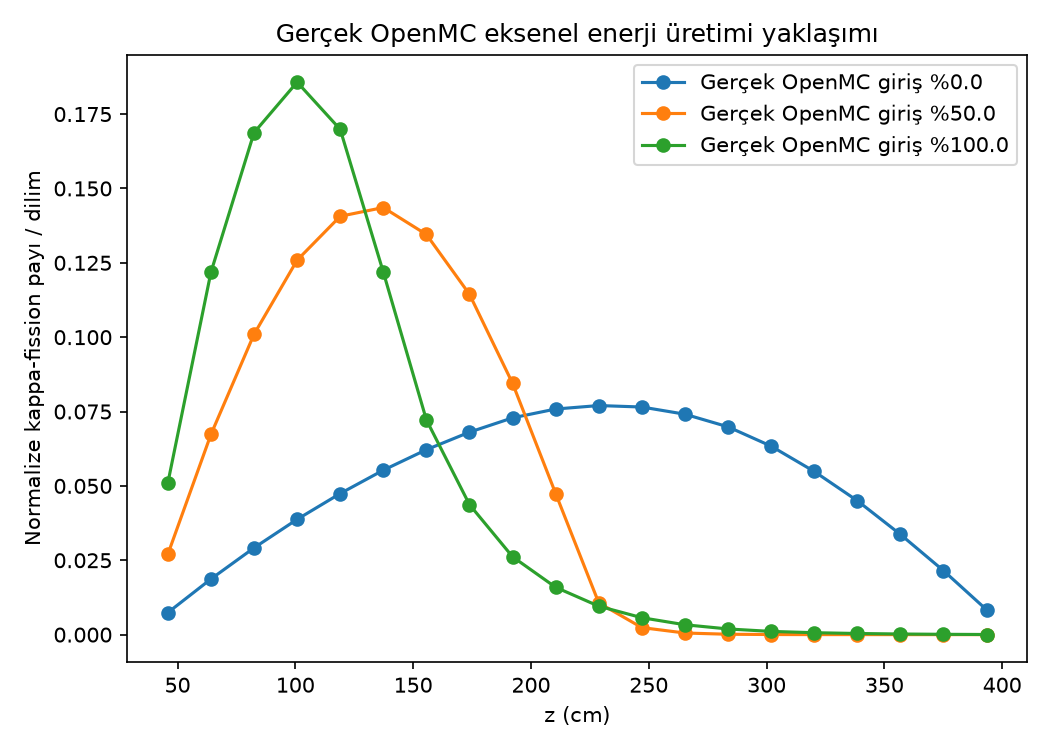

In [4]:
profiles=normalized.sum(axis=(2,3))
fig,ax=plt.subplots(figsize=(7,5))
for i in chosen:
    center=(z_edges[i,:-1]+z_edges[i,1:])/2
    ax.plot(center,profiles[i],marker='o',label=f'Gerçek OpenMC giriş %{insertion[i]:.1f}')
ax.set(xlabel='z (cm)',ylabel='Normalize kappa-fission payı / dilim',
       title='Gerçek OpenMC eksenel enerji üretimi yaklaşımı')
ax.legend();fig.tight_layout();fig.savefig(OUT/'openmc_axial_profiles.png',dpi=150);plt.show();plt.close(fig)
print('Üst dört dilim payları:',[(round(insertion[i],2),[round(float(v),7) for v in profiles[i,-4:]]) for i in chosen])


Bütün senaryolar: sıfır/yakıt 180434 / 1351680 ; düşük/yakıt 380837 / 1351680
Üst dört dilim: sıfır/yakıt 130944 / 270336 ; düşük/yakıt 203127 / 270336


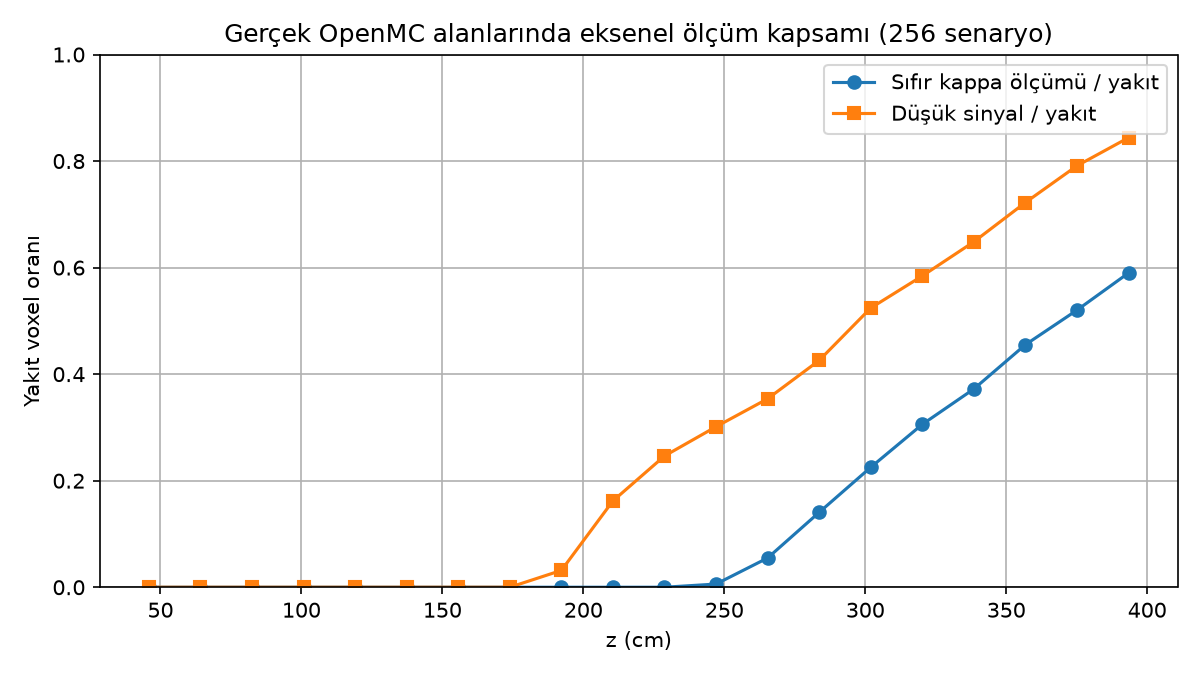

In [5]:
# Betimleyici kalite görünümü: bütün 256 alan, PCA bileşen seçimine girdi değildir.
axial_fuel=fuel.sum(axis=(0,2,3))
axial_zero_fraction=zero.sum(axis=(0,2,3))/axial_fuel
axial_low_fraction=low.sum(axis=(0,2,3))/axial_fuel
total_fuel=int(fuel.sum()); total_zero=int(zero.sum()); total_low=int(low.sum())
top_fuel=int(fuel[:,-4:].sum()); top_zero=int(zero[:,-4:].sum()); top_low=int(low[:,-4:].sum())
assert total_zero==180434 and total_low==380837
print('Bütün senaryolar: sıfır/yakıt',total_zero,'/',total_fuel,
      '; düşük/yakıt',total_low,'/',total_fuel)
print('Üst dört dilim: sıfır/yakıt',top_zero,'/',top_fuel,
      '; düşük/yakıt',top_low,'/',top_fuel)
fig,ax=plt.subplots(figsize=(8,4.5))
centers=(z_edges[0,:-1]+z_edges[0,1:])/2
ax.plot(centers,axial_zero_fraction,marker='o',label='Sıfır kappa ölçümü / yakıt')
ax.plot(centers,axial_low_fraction,marker='s',label='Düşük sinyal / yakıt')
ax.set(xlabel='z (cm)',ylabel='Yakıt voxel oranı',
       title='Gerçek OpenMC alanlarında eksenel ölçüm kapsamı (256 senaryo)')
ax.set_ylim(0,1);ax.legend();ax.grid(True)
fig.tight_layout();fig.savefig(OUT/'openmc_axial_signal_coverage.png',dpi=150);plt.show();plt.close(fig)


## 3. Eğitim bölümünde PCA/POD
208 eğitim alanı [z,y,x] C düzeninde 5.780 özellik olarak düzleştirilir. Dış yakıt hücreleri kaynak hedefte zaten sıfırdır; geometriye bağlı maskeler ayrıca saklanır. Standart PCA yalnız ortalamayı çıkarır, voxel bazında ölçekleme yapmaz. Bu PCA'nın kendi yeniden oluşturma hatasıdır; fiziksel parametrelerden katsayı **tahmin** hatası değildir.

Tek eğitim PCA birikimli varyans: [(1, 0.684733), (2, 0.891831), (4, 0.979134), (8, 0.997193), (12, 0.999595), (16, 0.999856), (24, 0.9999), (32, 0.999909), (48, 0.999922), (64, 0.999934), (96, 0.999953), (128, 0.99997)]


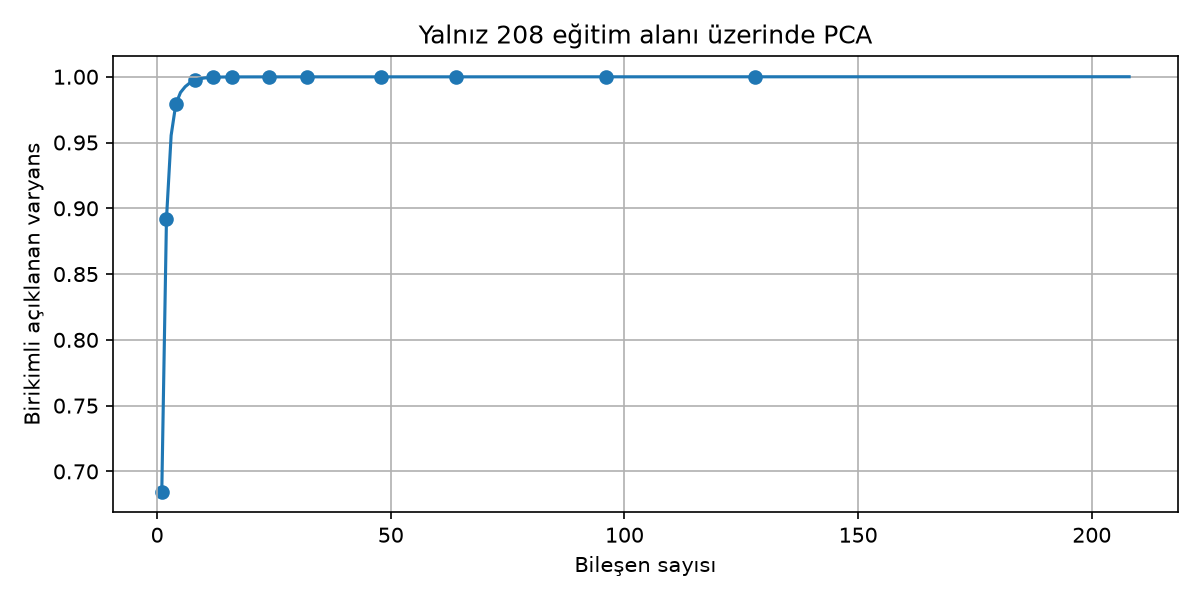

In [6]:
X=normalized.reshape(256,-1,order='C')
Xtr=X[train_idx]
mu=Xtr.mean(axis=0)
u,s,vt=np.linalg.svd(Xtr-mu,full_matrices=False)
ratio=s**2/(s**2).sum()
cumulative=np.cumsum(ratio)
ranks=[1,2,4,8,12,16,24,32,48,64,96,128]
print('Tek eğitim PCA birikimli varyans:',[(k,round(float(cumulative[k-1]),6)) for k in ranks])
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(np.arange(1,len(cumulative)+1),cumulative)
ax.scatter(ranks,[cumulative[k-1] for k in ranks])
ax.set(xlabel='Bileşen sayısı',ylabel='Birikimli açıklanan varyans',
       title='Yalnız 208 eğitim alanı üzerinde PCA')
ax.grid(True);fig.tight_layout();fig.savefig(OUT/'pca_explained_variance.png',dpi=150);plt.show();plt.close(fig)


## 4. Eğitim içi 5 katlı PCA yeniden oluşturma doğrulaması
Her kat için ortalama ve POD eksenleri yalnız dört eğitim katından öğrenilir. Hata, ayrılmış eğitim katının alanında hesaplanır. Ölçütler: örnek başına göreli L2 ve toplam payın L1 farkı. Test ve kalibrasyon burada kullanılmaz.

5 kat PCA CV süresi (s): 0.3
{'components': 1, 'explained_variance_full_train': 0.6847331525123648, 'cv_relative_l2_mean': 0.34815063431391996, 'cv_relative_l2_p95': 0.5906150040183383, 'cv_l1_share_mean': 0.41217618090764757}
{'components': 2, 'explained_variance_full_train': 0.8918310787945897, 'cv_relative_l2_mean': 0.20297795690024964, 'cv_relative_l2_p95': 0.3247252269140366, 'cv_l1_share_mean': 0.24940627878717955}
{'components': 4, 'explained_variance_full_train': 0.9791340861336352, 'cv_relative_l2_mean': 0.09129983491362278, 'cv_relative_l2_p95': 0.15049892200528125, 'cv_l1_share_mean': 0.10797310018415061}
{'components': 8, 'explained_variance_full_train': 0.9971931911776426, 'cv_relative_l2_mean': 0.03486633078061556, 'cv_relative_l2_p95': 0.05076668620359691, 'cv_l1_share_mean': 0.04048875517861121}
{'components': 12, 'explained_variance_full_train': 0.999594695707052, 'cv_relative_l2_mean': 0.014193408891569835, 'cv_relative_l2_p95': 0.02159732951081801, 'cv_l1_share_mean'

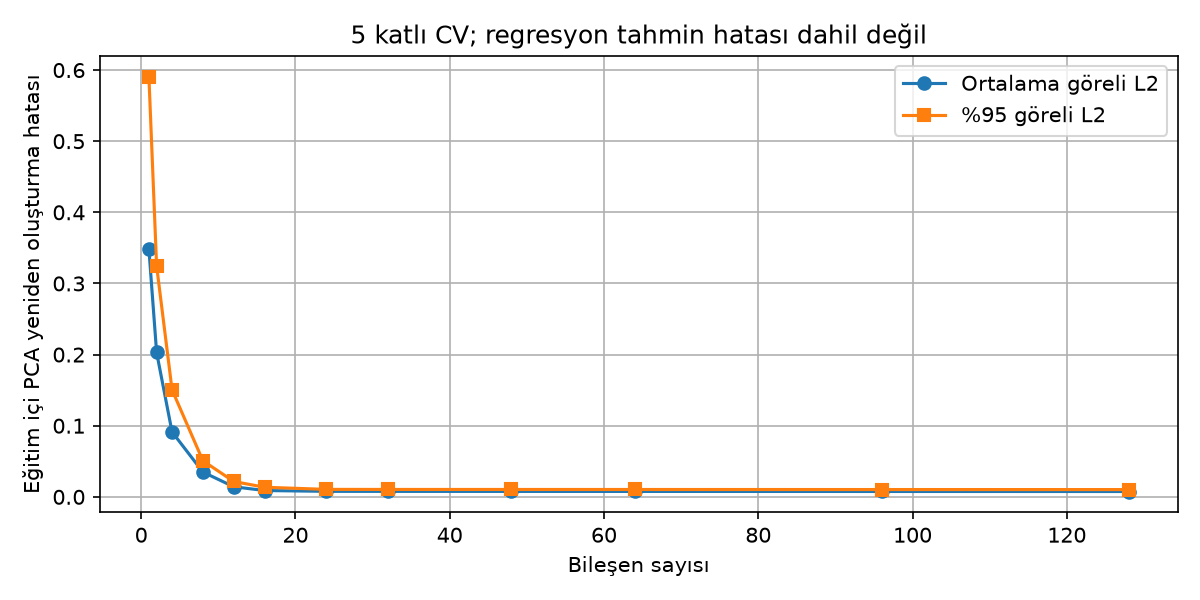

In [7]:
rng=np.random.default_rng(20261025)
perm=rng.permutation(len(train_idx))
folds=np.array_split(perm,5)
fold_l2={k:[] for k in ranks};fold_l1={k:[] for k in ranks}
start=time.monotonic()
for fold in folds:
    fit=np.setdiff1d(np.arange(len(train_idx)),fold,assume_unique=True)
    center=Xtr[fit].mean(axis=0)
    _,_,basis=np.linalg.svd(Xtr[fit]-center,full_matrices=False)
    held=Xtr[fold]
    scores=(held-center)@basis[:max(ranks)].T
    for k in ranks:
        reconstructed=center+scores[:,:k]@basis[:k]
        delta=reconstructed-held
        fold_l2[k].extend(np.linalg.norm(delta,axis=1)/np.linalg.norm(held,axis=1))
        fold_l1[k].extend(np.abs(delta).sum(axis=1))
cv=[{'components':k,'explained_variance_full_train':float(cumulative[k-1]),
     'cv_relative_l2_mean':float(np.mean(fold_l2[k])),'cv_relative_l2_p95':float(np.percentile(fold_l2[k],95)),
     'cv_l1_share_mean':float(np.mean(fold_l1[k]))} for k in ranks]
print('5 kat PCA CV süresi (s):',round(time.monotonic()-start,1))
for row in cv: print(row)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(ranks,[r['cv_relative_l2_mean'] for r in cv],marker='o',label='Ortalama göreli L2')
ax.plot(ranks,[r['cv_relative_l2_p95'] for r in cv],marker='s',label='%95 göreli L2')
ax.set(xlabel='Bileşen sayısı',ylabel='Eğitim içi PCA yeniden oluşturma hatası',
       title='5 katlı CV; regresyon tahmin hatası dahil değil')
ax.legend();ax.grid(True);fig.tight_layout();fig.savefig(OUT/'pca_cv_reconstruction_error.png',dpi=150);plt.show();plt.close(fig)


## 5. Gerçek ve yeniden oluşturulmuş alanlar
Gösterilen örnekler eğitim senaryolarıdır. Doğrusal PCA negatif değer oluşturabilir; görselde ve raporda işaretlenir, sessizce kırpılmaz veya yeniden normalize edilmez.

Örnek rank: 4 negatif voxel toplamı: 1882 negatif yakıt voxel: 1848 toplam negatif pay büyüklüğü: 0.027147811810421425 yeniden oluşturma toplamları: [1.0, 1.0, 1.0]


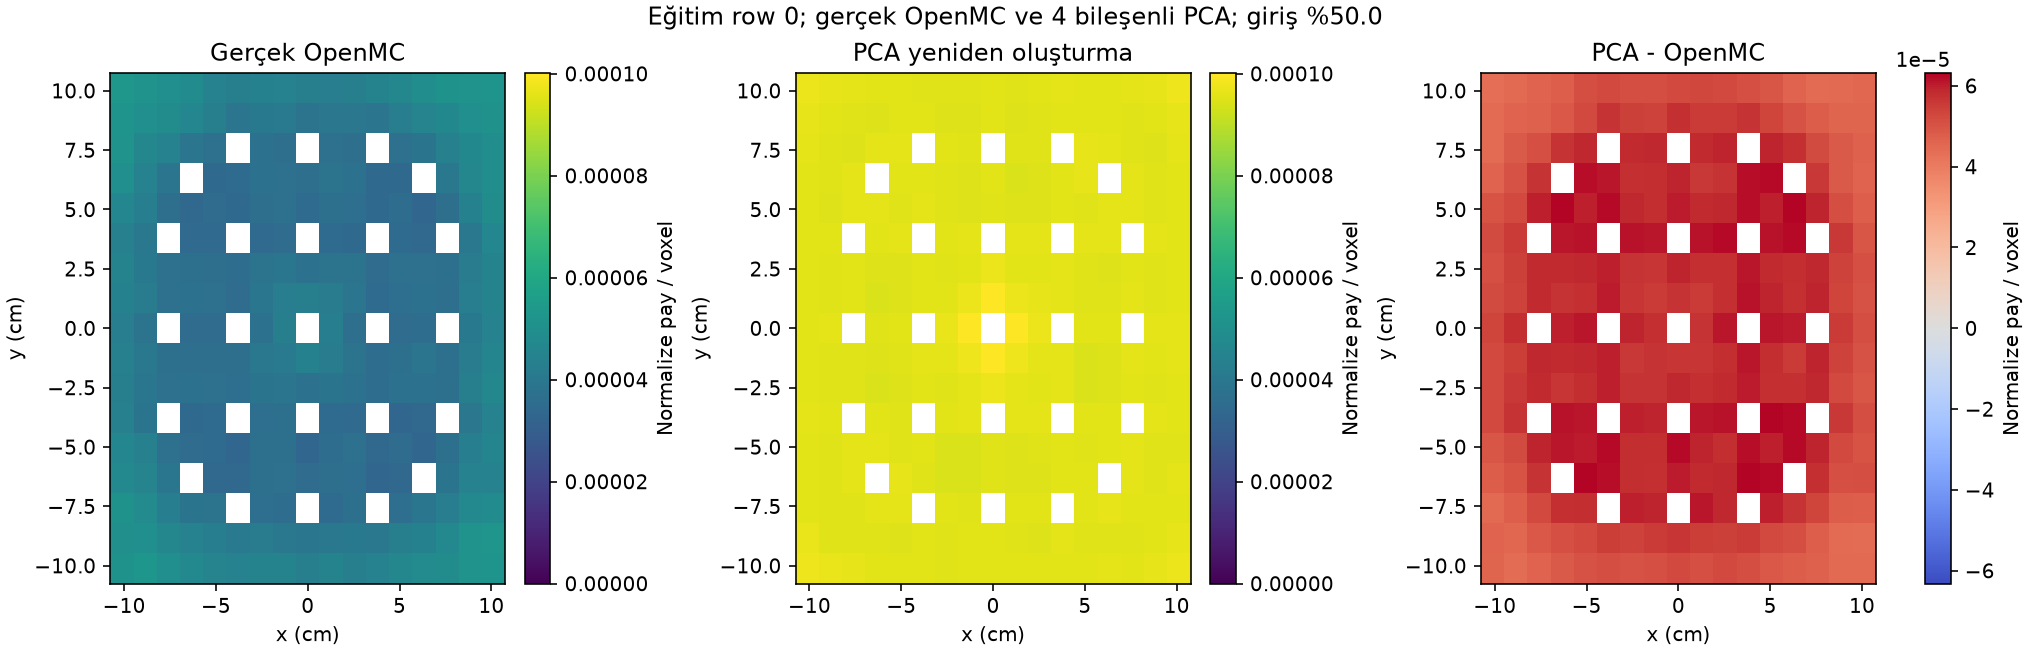

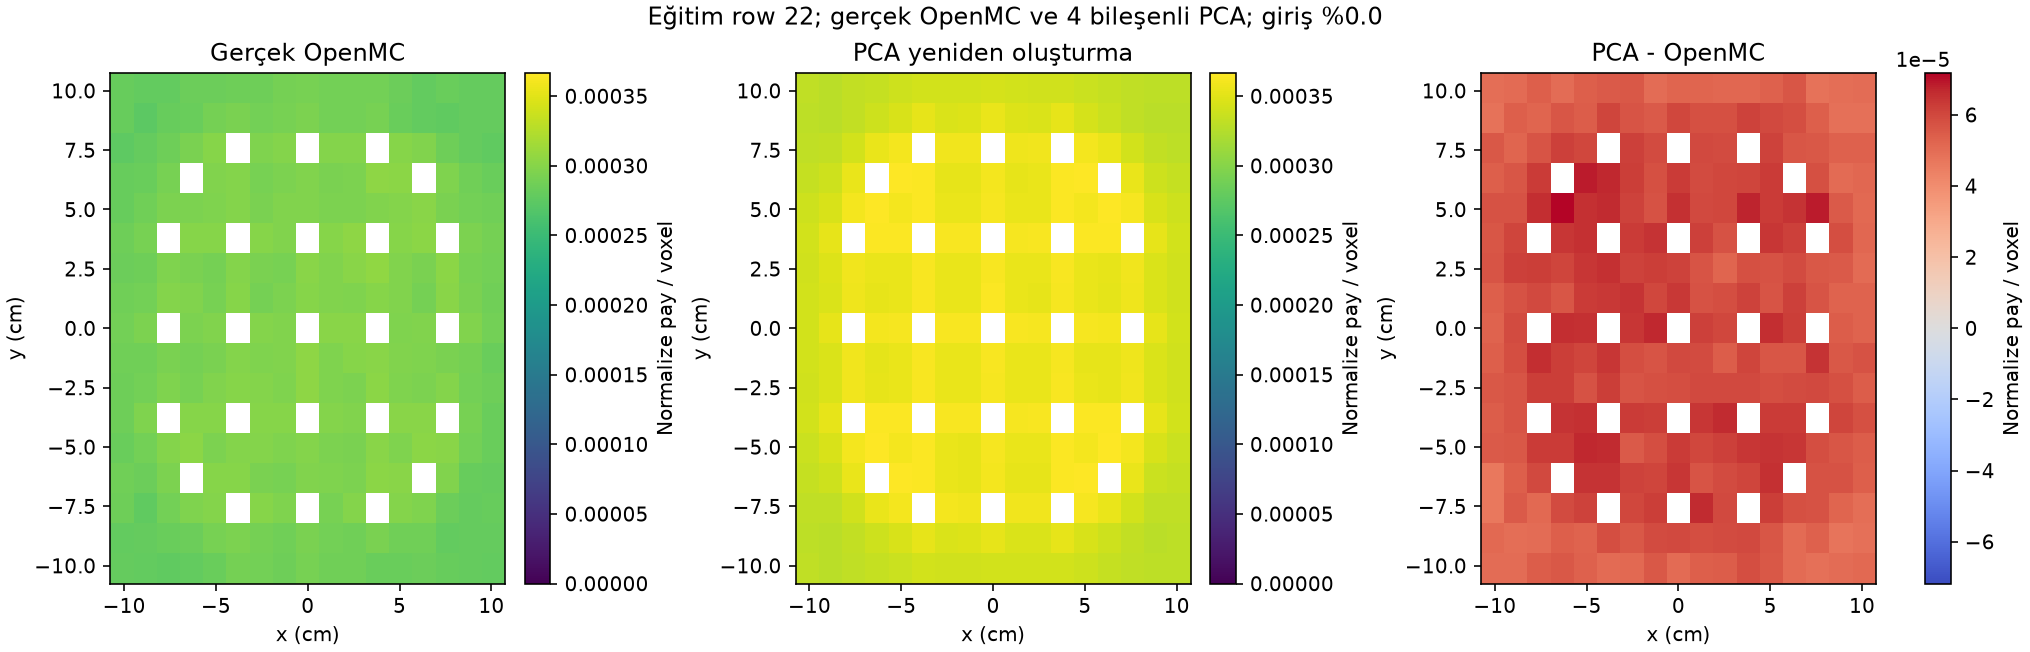

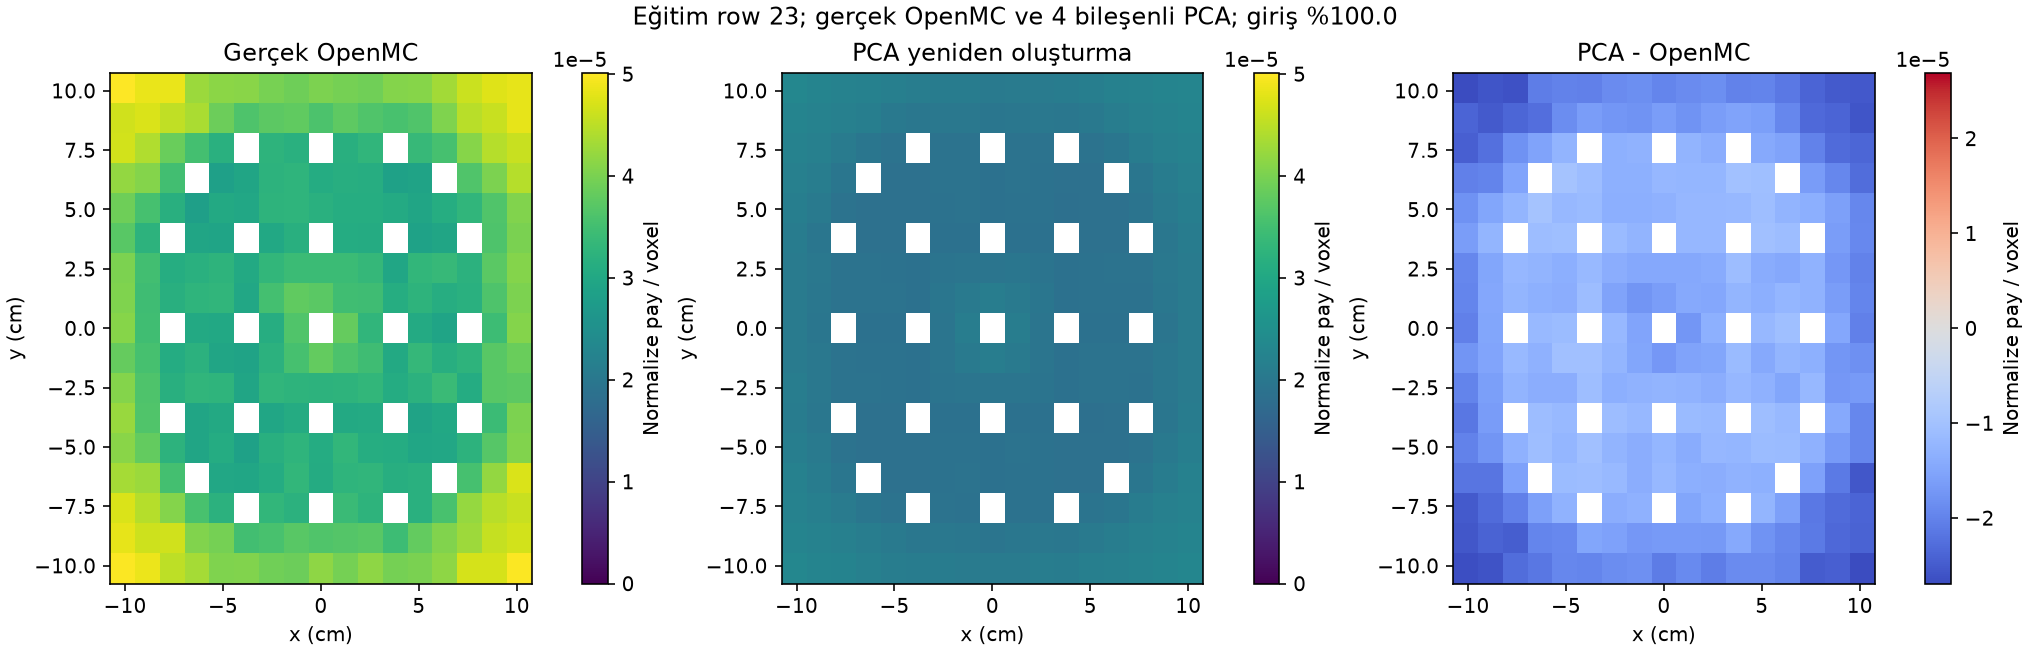

In [8]:
illustrative_k=min(ranks,key=lambda k:abs(cumulative[k-1]-0.95))
negative_recon=0; negative_recon_fuel=0; negative_mass=0.0; reconstruction_sums=[]
for i in chosen:
    scores=(X[i]-mu)@vt[:illustrative_k].T
    rec=(mu+scores@vt[:illustrative_k]).reshape(20,17,17)
    negative_recon+=int((rec<0).sum())
    negative_recon_fuel+=int(((rec<0)&fuel[i]).sum())
    negative_mass+=float(-rec[rec<0].sum())
    reconstruction_sums.append(float(rec.sum()))
    zmid=10
    actual=np.ma.masked_where(~fuel[i,zmid],normalized[i,zmid])
    fitted=np.ma.masked_where(~fuel[i,zmid],rec[zmid])
    residual=fitted-actual
    vmax=max(float(actual.max()),float(fitted.max()))
    vmin=min(float(actual.min()),float(fitted.min()),0.0)
    lim=max(abs(float(residual.min())),abs(float(residual.max())))
    fig,axes=plt.subplots(1,3,figsize=(14,4.5),constrained_layout=True)
    for ax,field,title in zip(axes,(actual,fitted,residual),('Gerçek OpenMC','PCA yeniden oluşturma','PCA - OpenMC')):
        kw={'vmin':-lim,'vmax':lim,'cmap':'coolwarm'} if title=='PCA - OpenMC' else {'vmin':vmin,'vmax':vmax,'cmap':'viridis'}
        im=ax.pcolormesh(x_edges[i],y_edges[i],field,shading='flat',**kw)
        fig.colorbar(im,ax=ax,label='Normalize pay / voxel')
        ax.set(title=title,xlabel='x (cm)',ylabel='y (cm)')
    fig.suptitle(f'Eğitim row {i}; gerçek OpenMC ve {illustrative_k} bileşenli PCA; giriş %{insertion[i]:.1f}')
    fig.savefig(OUT/f'pca_compare_row_{i:03d}.png',dpi=145)
    plt.show();plt.close(fig)
print('Örnek rank:',illustrative_k,'negatif voxel toplamı:',negative_recon,
      'negatif yakıt voxel:',negative_recon_fuel,
      'toplam negatif pay büyüklüğü:',negative_mass,
      'yeniden oluşturma toplamları:',reconstruction_sums)


## 6. Sonuç kaydı ve sonraki aşama
İlk katsayı-regresyon pilotunda **8, 12, 16 ve 24** bileşen ayrı aday olarak karşılaştırılabilir. Eğitim içi PCA yeniden oluşturma göreli L2 ortalamaları sırasıyla yaklaşık %3,49, %1,42, %0,89 ve %0,78'dir; 24 sonrası iyileşme küçüktür. Bu sayılar yalnız temsil hatasıdır. Sekiz fiziksel girdiden katsayı tahmininin hatası ayrıca eğitim içi CV ile ölçülmelidir; nihai bileşen sayısı şimdi onaylanmış değildir. Kalibrasyon/test bileşen seçimine kullanılmadı. Doğrusal PCA negatif değer üretebilir; bunun fiziksel işlemesi ileride ayrıca kararlaştırılmalıdır.


In [9]:
milestones={}
for threshold in (0.90,0.95,0.99):
    hit=np.flatnonzero(cumulative>=threshold)
    milestones[str(threshold)]=int(hit[0]+1) if len(hit) else None
summary={'schema':'openmc_field3d_pca_exploratory_v1',
 'source_fields_sha256':hashlib.sha256((DATA/'fields.npz').read_bytes()).hexdigest(),
 'source_splits_sha256':hashlib.sha256((DATA/'splits.json').read_bytes()).hexdigest(),
 'source_manifest_sha256':hashlib.sha256((DATA/'dataset_manifest.json').read_bytes()).hexdigest(),
 'status':'PCA exploratory only; field3d REVIEW_REQUIRED; no regression, MC, physical acceptance',
 'total_fuel_voxels':total_fuel,'total_zero_fuel_voxels':total_zero,
 'total_low_signal_fuel_voxels':total_low,'top4_fuel_voxels':top_fuel,
 'top4_zero_fuel_voxels':top_zero,'top4_low_signal_fuel_voxels':top_low,
 'shape':list(normalized.shape),'flatten_order':'C [z,y,x], x fastest',
 'train_count':len(train_idx),'calibration_count':25,'test_count':23,
 'examples':[{'row':int(i),'scenario_id':scenarios[i]['scenario_id'],'insertion_percent':float(insertion[i]),
              'zero_fuel_voxels':int(zero[i].sum()),'low_signal_fuel_voxels':int(low[i].sum()),
              'top4_zero':int(zero[i,-4:].sum()),'top4_low':int(low[i,-4:].sum())} for i in chosen],
 'mask_same_all':bool(np.all(fuel==fuel[0])),'x_edges_same_all':bool(np.all(x_edges==x_edges[0])),
 'negative_raw':int((raw<0).sum()),'negative_normalized':int((normalized<0).sum()),
 'negative_reconstructed_example_voxels':negative_recon,
 'negative_reconstructed_example_fuel_voxels':negative_recon_fuel,
 'negative_reconstructed_example_mass':negative_mass,
 'reconstructed_example_sums':reconstruction_sums,
 'normalized_sum_min_max':[float(normalized.sum(axis=(1,2,3)).min()),float(normalized.sum(axis=(1,2,3)).max())],
 'variance_milestone_rank':milestones,'cv':cv,'illustrative_rank':illustrative_k,
 'recommendation':'Use CV reconstruction and coefficient-regression CV together; variance milestone alone is not an acceptance threshold. Test remains untouched.'}
(OUT/'pca_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
print('Varyans eşikleri için en küçük rank (yalnız açıklayıcı):',milestones)
print('Grafikler ve özet:',OUT)


Varyans eşikleri için en küçük rank (yalnız açıklayıcı): {'0.9': 3, '0.95': 3, '0.99': 6}
Grafikler ve özet: /home/ascanipek/openmc-proje/reports/field3d_pca_v1
